In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import anndata
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [4]:
sb.set_palette('colorblind')

In [5]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [6]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Load data

In [7]:
###### CONSTITUTIVE - SPI1 with majority voting being HSC_MPP or CYCLING_MPP
constitutive = sc.read('write/SPI1_CONSTITUTIVE_selected_data_raw_count.h5ad')
# transfer celltypist prediction 
con_hsc = sc.read('write/SPI1_CONSTITUTIVE_selected_HSC.h5ad')
constitutive = constitutive[con_hsc.obs_names]
constitutive.obs['annot'] = con_hsc.obs['majority_voting']
# only keep the ones with SPI1
constitutive = constitutive[constitutive.obs['TF_calling']=='EXOG_SPI1']

/tmp/ipykernel_75688/4091712208.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  constitutive.obs['annot'] = con_hsc.obs['majority_voting']


In [8]:
Counter(constitutive.obs['annot'])

Counter({'HSC_MPP': 29, 'CYCLING_MPP': 17})

In [9]:
###### INDUCIBLE - SPI1 with leiden cluster annotated as HSC_MPP or CYCLING_MPP, and only keep SPI1_DOX_D8 (from SPI1_INDUCIBLE.A03.v01.annotation.ipynb)
inducible = sc.read('write/SPI1_INDUCIBLE_data_raw_count.h5ad')
# transfer annotation 
ind_hsc = sc.read('write/SPI1_INDUCIBLE_HSC.h5ad')
inducible = inducible[ind_hsc.obs_names]
inducible.obs['annot'] = ind_hsc.obs['annot']
# only leave SPI1_DOX_D8
inducible = inducible[inducible.obs['sanger_sample_ID']=='HSC_D18_INDUC_SPI1_DOX_D8']

/tmp/ipykernel_75688/1092381377.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  inducible.obs['annot'] = ind_hsc.obs['annot']


In [10]:
Counter(inducible.obs['annot'])

Counter({'HSC_MPP': 1568, 'CYCLING_MPP': 211})

In [11]:
panfetal = sc.read_h5ad('reference_data_HSC/PAN.A01.v01.raw_count.20210429.HSC_PROGENITORS.embedding.h5ad')

In [12]:
# panfetal - only take HSC_MPP or CYCLING_MPP from YS, LI, BM
panfetal = panfetal[panfetal.obs['anno_lvl_2_final_clean'].isin(['HSC_MPP','CYCLING_MPP'])]
panfetal = panfetal[panfetal.obs['organ'].isin(['YS','LI','BM'])]
panfetal.obs['annot'] = panfetal.obs['anno_lvl_2_final_clean'].astype('str')

/tmp/ipykernel_75688/898122397.py:4: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  panfetal.obs['annot'] = panfetal.obs['anno_lvl_2_final_clean'].astype('str')


In [13]:
Counter(panfetal.obs['organ'])

Counter({'LI': 4724, 'BM': 566, 'YS': 273})

In [14]:
# set batch
constitutive.obs['batch'] = 'in_vitro_con'
inducible.obs['batch'] = 'in_vitro_ind'
panfetal.obs['batch'] = 'in_vivo'+'_'+panfetal.obs['organ'].astype('str')

/tmp/ipykernel_75688/995732351.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  constitutive.obs['batch'] = 'in_vitro_con'
/tmp/ipykernel_75688/995732351.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  inducible.obs['batch'] = 'in_vitro_ind'


In [15]:
gene_common =  list(set(constitutive.var_names) & set(panfetal.var_names))
constitutive = constitutive[:,gene_common]
inducible = inducible[:,gene_common]
panfetal = panfetal[:,gene_common]

In [16]:
## Merge
adata = anndata.concat([panfetal, constitutive, inducible], axis=0,
                              join="outer", merge="unique", uns_merge="unique")

In [17]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Marker gene plot

In [18]:
adata.obs['batch_annot']=adata.obs['batch'].astype('str') + '-' + adata.obs['annot'].astype('str')

In [22]:
adata.obs['batch'] = adata.obs['batch'].cat.reorder_categories(['in_vivo_YS','in_vivo_LI', 'in_vivo_BM', 
    'in_vitro_con', 'in_vitro_ind'])

Marker genes from https://www.science.org/doi/10.1126/science.add7564 figure 3 and panfetal paper

In [19]:
genes = {'Canonical HSC':['CD34','MLLT3','SPINK2','HOPX','HLF','RAB27B','MYB'],
'Early HSC':['DDIT4','SLC2A3','RGS16','LIN28A',],
'Definitive HSC':['KIT','ITGA4','CD74','PROCR','EMCN','GBP4','ACE'],
'Patterning':['HOXA7','HOXA9','HOXA10','HOXB7','HOXB9'],

'MLP':['BCL11A','IL7R','IL2RG'],
'B lineage':['CD19','PAX5'],
'T lineage':['CD3D','BCL11B'],
'MEMP':['GATA2'],
'MEP':['KLF1','ITGA2B'],
'Ery lineage':['HBB','HBG1'],
'Myeloid lineage':['MPO','CSF1R','CEBPA'],
    'Proliferation':['MKI67']
}

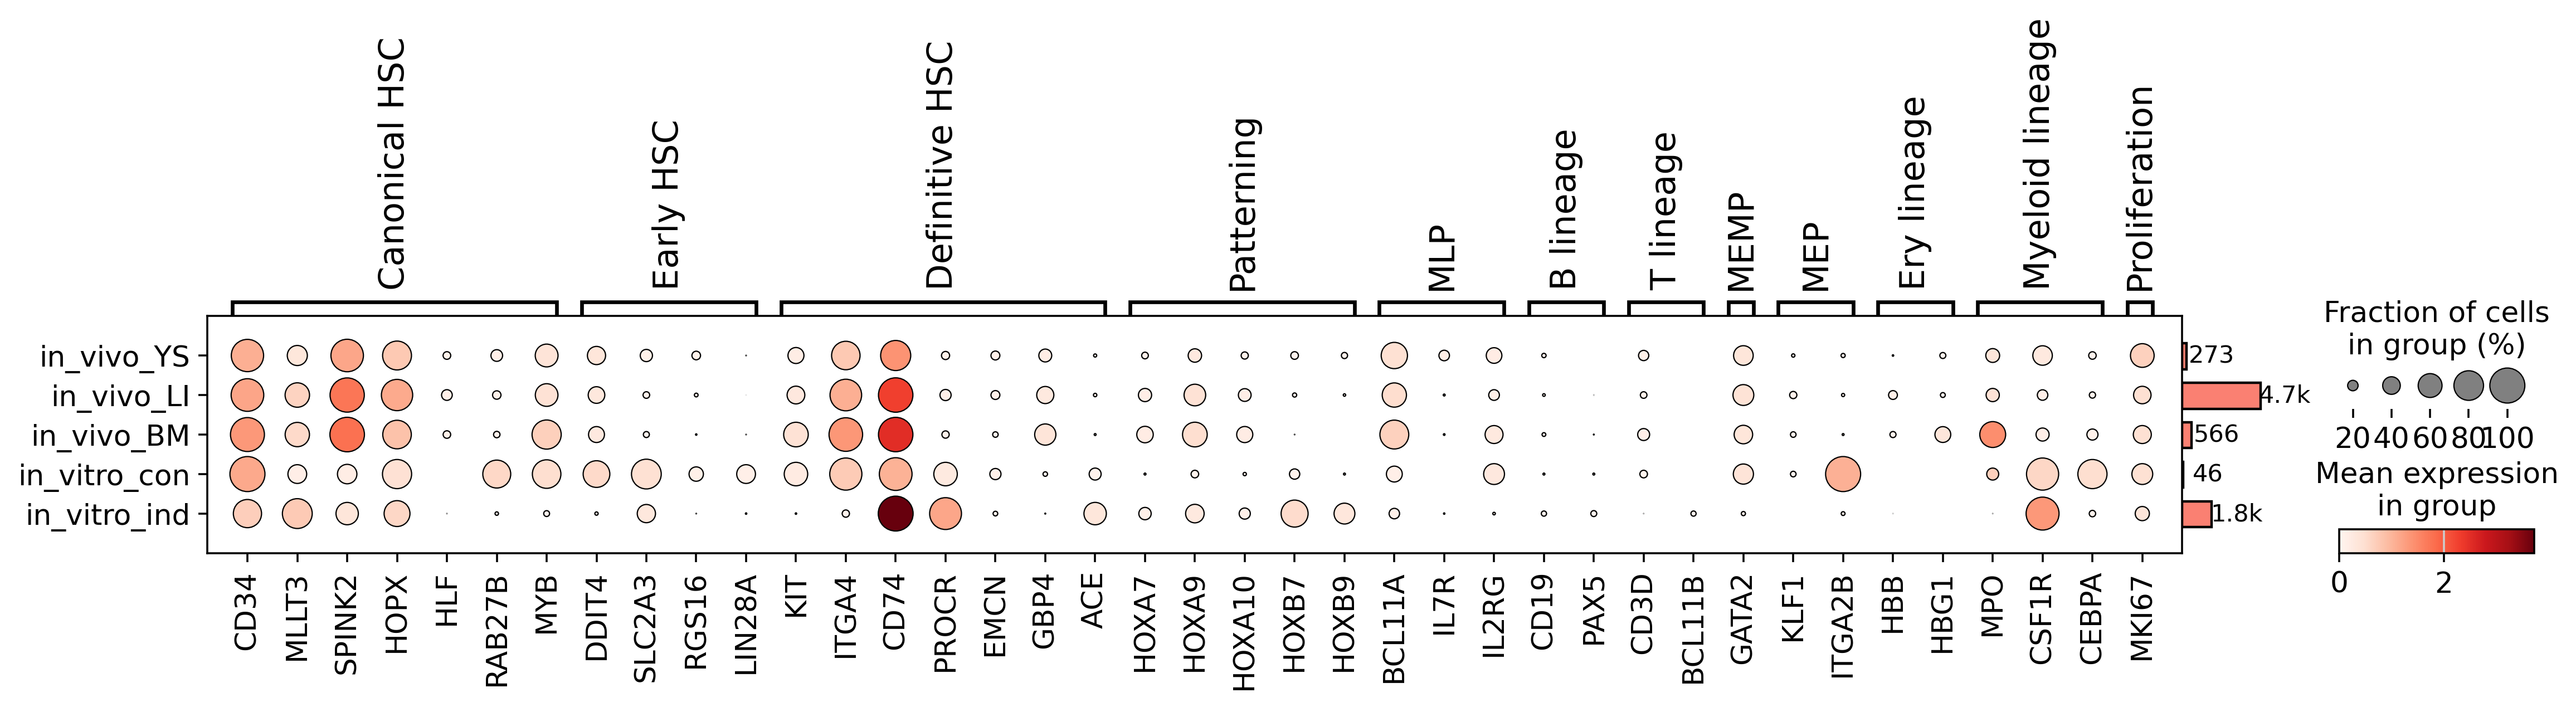

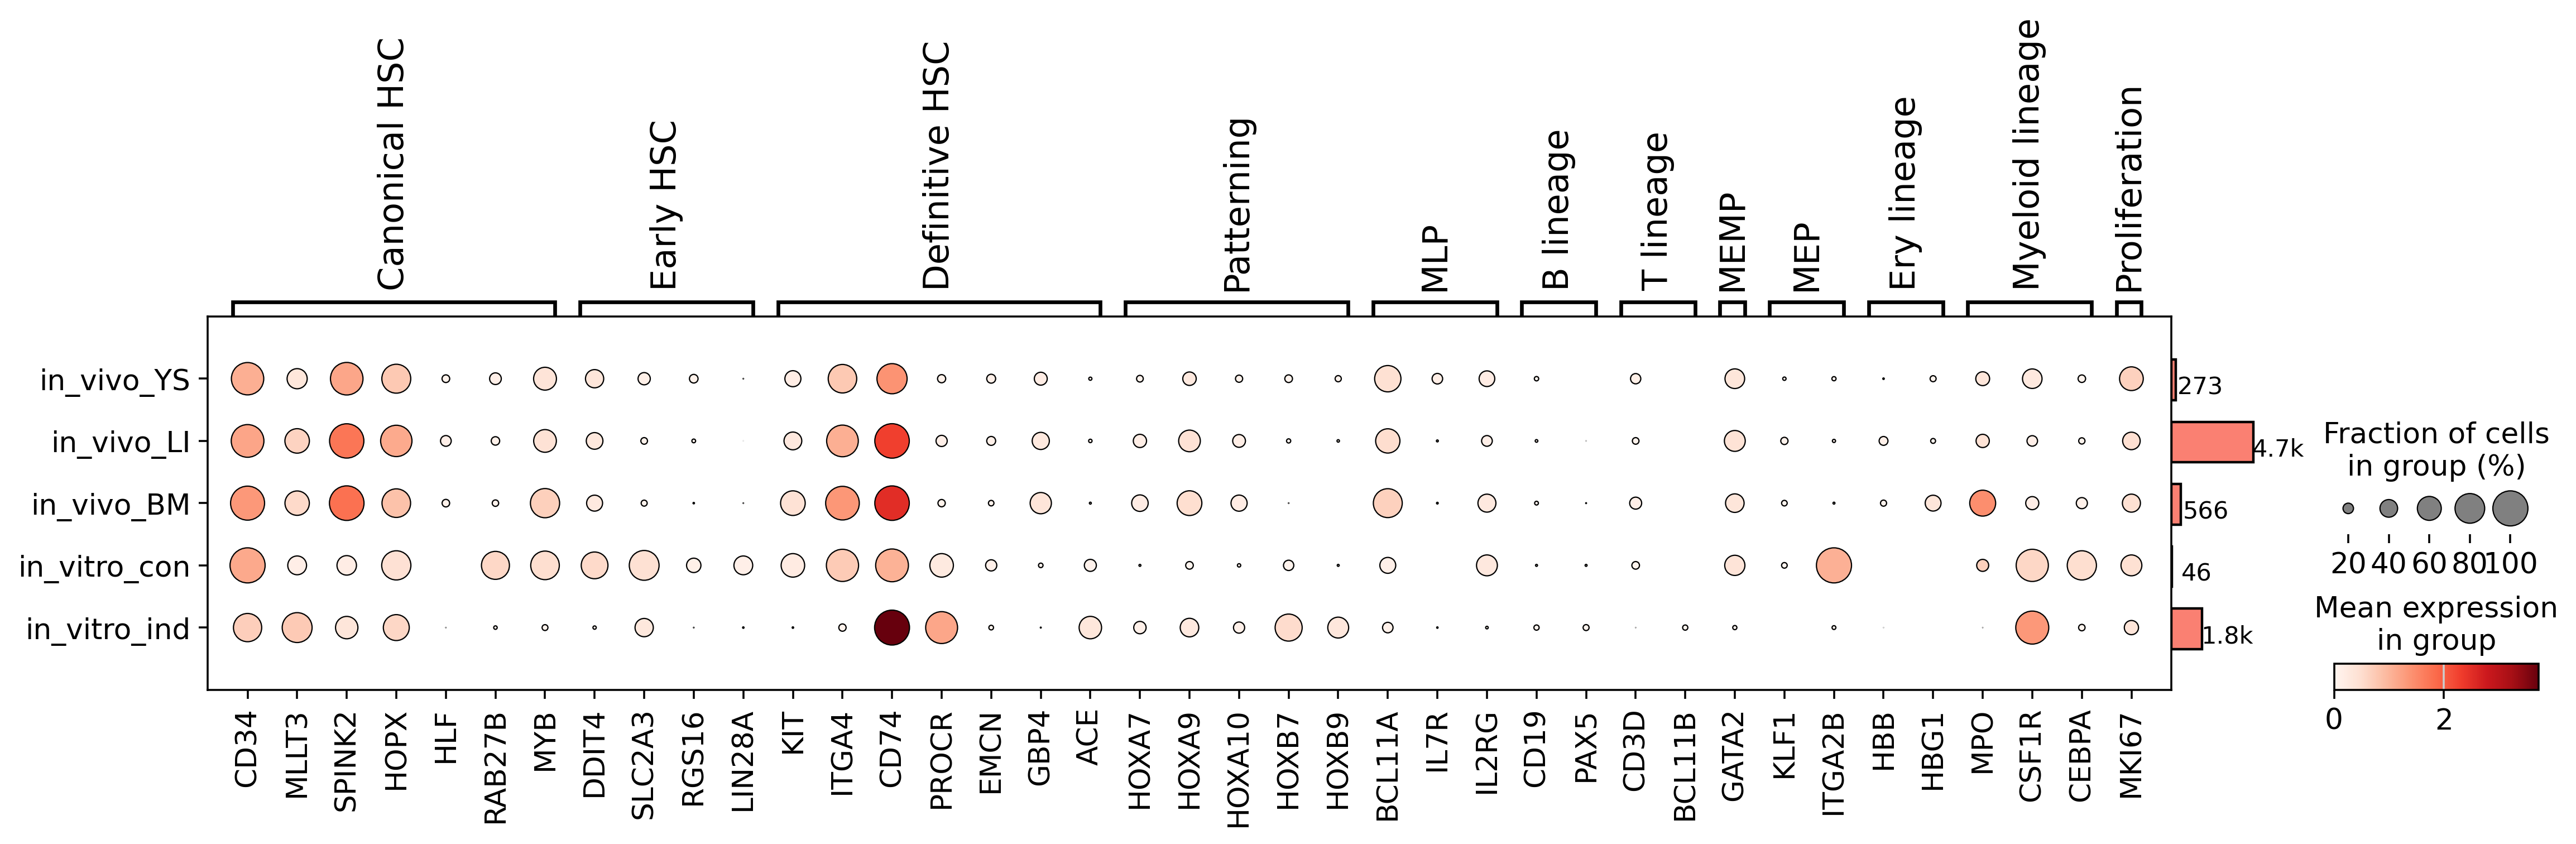

In [23]:
dp = sc.pl.dotplot(adata, genes, 'batch', return_fig=True)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

dp.savefig(fig_path+"SPI1_in_vivo_all_dotplot.pdf", bbox_inches="tight")